# M18K V2 — Classical Otsu Baseline vs. WB-only YOLO

**Purpose:** a small course-project experiment on the **same 10 held-out test images** (seed 42):

1. Implement **Otsu thresholding from scratch** and verify against OpenCV.
2. Segment bright mushroom-like regions using grayscale + Gaussian blur + Otsu + morphology + connected components.
3. Run two one-change ablations: **no blur** and **no morphology**.
4. Compare baseline/ablations with the existing **WB-only YOLOv8n-seg** checkpoint using ground-truth **foreground union IoU / Dice** and **per-image count absolute error**.

**Scope:** No training, no full-dataset audit. This is a small illustrative comparison (not a new full-test mAP result). Existing RGB test images and COCO annotations must be accessible via Google Drive.

In [3]:
%pip -q install "ultralytics>=8.3,<9" pycocotools gdown opencv-python-headless pandas matplotlib psutil

In [4]:
from pathlib import Path
import os, time, random, json, zipfile
import numpy as np
import pandas as pd
import cv2, gdown, torch, psutil
import matplotlib.pyplot as plt
from pycocotools.coco import COCO
from ultralytics import YOLO
from IPython.display import display

# Use the same test directory and random sampling convention as our inference demo.
DATA_ROOT = Path("/content/drive/MyDrive/M18K_Reproduction/M18K_V2_data/M18KV2")
ALTERNATE_DATA_ROOT = Path("/content/drive/MyDrive/Colab Notebooks/M18K_Reproduction/M18KV2")
MODEL_GDRIVE_ID = "1Q5iq_-j-RwOTkyiiXyTOc80Cf_xwk7K-"
MODEL_PATH = Path("/content/khang_wb_best.pt")
SAMPLE_SIZE = 10     # Keep the experiment small; can change to 30 if desired.
SEED = 42
IMGSZ, CONF, NMS_IOU, MAX_DET = 640, 0.25, 0.7, 1000
MIN_COMPONENT_AREA = 100  # Pixels; same threshold in classical baseline and ablations.
OUT = Path("/content/M18K_Otsu_Comparison")
OUT.mkdir(parents=True, exist_ok=True)

# Mount Google Drive only when needed.
if not Path("/content/drive/MyDrive").exists():
    from google.colab import drive
    drive.mount("/content/drive")
if not (DATA_ROOT / "test" / "rgb").is_dir():
    DATA_ROOT = ALTERNATE_DATA_ROOT
RGB_DIR = DATA_ROOT / "test" / "rgb"
COCO_JSON = DATA_ROOT / "test" / "annotations_coco.json"
assert RGB_DIR.is_dir(), f"Test RGB folder not visible. Set DATA_ROOT correctly: {RGB_DIR}"
assert COCO_JSON.is_file(), f"COCO annotations not visible: {COCO_JSON}"

paths = sorted(p for p in RGB_DIR.iterdir() if p.suffix.lower() in {".png", ".jpg", ".jpeg"})
assert len(paths) >= SAMPLE_SIZE, f"Found only {len(paths)} test images"
selected = random.Random(SEED).sample(paths, SAMPLE_SIZE)
print(f"Selected {len(selected)} / {len(paths)} test images")
print("Output folder:", OUT)
print("Images:", [p.name for p in selected])

Mounted at /content/drive
Selected 10 / 450 test images
Output folder: /content/M18K_Otsu_Comparison
Images: ['004373.png', '004103.png', '004058.png', '004425.png', '004186.png', '004171.png', '004160.png', '004117.png', '004423.png', '004098.png']


## 1. Otsu thresholding from scratch

For each candidate threshold, compute the between-class variance from the 256-bin grayscale histogram. Select the threshold maximizing it. OpenCV is used **only for verification**, not inside our custom Otsu implementation.

In [5]:
def otsu_scratch(gray: np.ndarray):
    """Return (Otsu threshold, 0/255 binary image) for uint8 grayscale input."""
    if gray.ndim != 2 or gray.dtype != np.uint8:
        raise ValueError("Expected uint8 grayscale image")
    hist = np.bincount(gray.ravel(), minlength=256).astype(np.float64)
    prob = hist / gray.size
    w0 = np.cumsum(prob)
    mu = np.cumsum(prob * np.arange(256))
    mu_total = mu[-1]
    denominator = w0 * (1.0 - w0)
    score = np.full(256, -1.0, dtype=np.float64)
    valid = denominator > 0
    score[valid] = (mu_total * w0[valid] - mu[valid]) ** 2 / denominator[valid]
    threshold = int(np.argmax(score))
    mask = np.where(gray > threshold, 255, 0).astype(np.uint8)
    return threshold, mask

# Two implementation sanity cases. OpenCV's tie choice is usually the first maximum.
for arr in [np.array([[0,0,50,50,200,200,255,255]], dtype=np.uint8),
            np.array([[50,50,50,50]], dtype=np.uint8)]:
    t_my, m_my = otsu_scratch(arr)
    t_cv, m_cv = cv2.threshold(arr, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    print("scratch / OpenCV threshold:", t_my, int(t_cv),
          "exact binary agreement:", bool(np.array_equal(m_my, m_cv)))


scratch / OpenCV threshold: 50 50 exact binary agreement: True
scratch / OpenCV threshold: 0 0 exact binary agreement: True


## 2. Classical segmentation and ablations

The classical method is a **foreground mask**, not an instance segmentation model. Connected components provide a simple count; touching mushroom caps can merge into one component. This limitation is expected.

In [6]:
def classical_segment(rgb: np.ndarray, blur=True, morph=True):
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    blurred = cv2.GaussianBlur(gray, (5,5), 0) if blur else gray
    t, binary = otsu_scratch(blurred)
    if morph:
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3,3))
        binary = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
    n, labels, stats, _ = cv2.connectedComponentsWithStats(binary, 8)
    keep = np.flatnonzero(stats[1:, cv2.CC_STAT_AREA] >= MIN_COMPONENT_AREA) + 1
    foreground = np.isin(labels, keep)  # Include only large enough components.
    return foreground, len(keep), t

def semantic_metrics(pred: np.ndarray, gt: np.ndarray):
    pred, gt = pred.astype(bool), gt.astype(bool)
    intersection = int(np.count_nonzero(pred & gt))
    n_pred = int(np.count_nonzero(pred))
    n_gt = int(np.count_nonzero(gt))
    union = n_pred + n_gt - intersection
    iou = intersection / union if union else 1.0
    dice = (2 * intersection / (n_pred + n_gt)) if (n_pred + n_gt) else 1.0
    return iou, dice

variants = {
    "Otsu_full": (True, True),
    "Otsu_no_blur": (False, True),
    "Otsu_no_morph": (True, False),
}


## 3. Load matching ground truth and the existing WB-only model

COCO `WB` polygons are rasterized with `pycocotools` and combined into **one foreground-union mask per image**. YOLO predicted instance masks are combined the same way for the IoU/Dice comparison. This compares **foreground coverage**, not COCO instance AP.

In [7]:
coco = COCO(str(COCO_JSON))
wb_categories = [c["id"] for c in coco.dataset["categories"]
                 if c.get("name", "").strip().lower() in {"wb", "white button", "white button mushroom"}]
assert len(wb_categories) == 1, f"Could not uniquely identify WB in: {coco.dataset['categories']}"
WB_CAT_ID = wb_categories[0]
image_by_basename = {Path(rec["file_name"]).name: rec for rec in coco.dataset["images"]}
assert all(p.name in image_by_basename for p in selected), "Some selected filenames absent from test COCO JSON"

if not MODEL_PATH.is_file():
    gdown.download(id=MODEL_GDRIVE_ID, output=str(MODEL_PATH), quiet=False)
assert MODEL_PATH.is_file() and MODEL_PATH.stat().st_size > 100_000, "Checkpoint download failed"
model = YOLO(str(MODEL_PATH))
assert len(model.names) == 1, f"Expected WB-only checkpoint; got {model.names}"
device = 0 if torch.cuda.is_available() else "cpu"
print("WB category ID:", WB_CAT_ID, "YOLO model:", model.names, "device:", device)

def gt_union_for(path, h, w):
    img = image_by_basename[path.name]
    ann_ids = coco.getAnnIds(imgIds=[img["id"]], catIds=[WB_CAT_ID], iscrowd=None)
    anns = coco.loadAnns(ann_ids)
    mask = np.zeros((h,w), dtype=bool)
    for ann in anns:
        if ann.get("segmentation"):
            instance_mask = coco.annToMask(ann).astype(bool)
            if instance_mask.shape != (h,w):
                raise ValueError(f"GT image-size mismatch for {path.name}")
            mask |= instance_mask
    return mask, len(anns)

def yolo_inference(path, shape):
    h,w = shape
    result = model.predict(source=str(path), imgsz=IMGSZ, conf=CONF,
        iou=NMS_IOU, max_det=MAX_DET, retina_masks=True,
        device=device, verbose=False)[0]
    mask = np.zeros((h,w), dtype=bool)
    n = len(result.boxes) if result.boxes is not None else 0
    if result.masks is not None:
        for individual in result.masks.data.cpu().numpy():
            if individual.shape != (h,w):
                individual = cv2.resize(individual.astype(np.uint8), (w,h),
                                        interpolation=cv2.INTER_NEAREST)
            mask |= (individual > 0)
    return mask, n


loading annotations into memory...
Done (t=7.20s)
creating index...
index created!


Downloading...
From: https://drive.google.com/uc?id=1Q5iq_-j-RwOTkyiiXyTOc80Cf_xwk7K-
To: /content/khang_wb_best.pt
100%|██████████| 7.01M/7.01M [00:00<00:00, 144MB/s]


WB category ID: 2 YOLO model: {0: 'WB'} device: cpu


## 4. Evaluate the same images and export results

Measure each method's foreground union IoU, Dice, and count absolute error against the same WB ground truth. Runtime includes the method call; YOLO's first-image initialization may make its reported time less stable. No full-test mAP is calculated here.

In [8]:
rows = []
otsu_checks = []
previews = []
proc = psutil.Process(os.getpid())

for idx, path in enumerate(selected, start=1):
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    assert bgr is not None, f"Failed to read {path}"
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    h,w = rgb.shape[:2]
    gt, n_gt = gt_union_for(path, h, w)

    # Verification: the SAME grayscale+Gaussian input for scratch and OpenCV.
    blurred = cv2.GaussianBlur(cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY), (5,5), 0)
    t_s, mask_s = otsu_scratch(blurred)
    t_cv, mask_cv = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    pixel_match = float(np.mean(mask_s == mask_cv))
    otsu_checks.append({"image":path.name, "scratch_threshold":t_s,
                        "opencv_threshold":int(t_cv), "pixel_agreement":pixel_match,
                        "exact_match":bool(np.array_equal(mask_s,mask_cv))})

    classical_masks = {}
    for method,(do_blur,do_morph) in variants.items():
        t0 = time.perf_counter()
        foreground, count, t = classical_segment(rgb, do_blur, do_morph)
        elapsed_ms = (time.perf_counter()-t0)*1000
        iou,dice = semantic_metrics(foreground,gt)
        rows.append({"image":path.name,"method":method,"gt_count":n_gt,
                    "pred_count":int(count), "count_abs_error":abs(count-n_gt),
                    "union_IoU":iou,"union_Dice":dice,"runtime_ms":elapsed_ms,
                    "otsu_threshold":t,"device":"CPU"})
        classical_masks[method] = foreground

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    yolo_mask, n_yolo = yolo_inference(path,(h,w))
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    yolo_ms = (time.perf_counter()-t0)*1000
    iou,dice = semantic_metrics(yolo_mask, gt)
    rows.append({"image":path.name, "method":"YOLO_WB_only", "gt_count":n_gt,
                "pred_count":int(n_yolo), "count_abs_error":abs(n_yolo-n_gt),
                "union_IoU":iou, "union_Dice":dice, "runtime_ms":yolo_ms,
                "otsu_threshold":None, "device":"GPU" if torch.cuda.is_available() else "CPU"})

    if len(previews)<3: previews.append((path.name,rgb,gt,classical_masks["Otsu_full"],yolo_mask))
    print(f"{idx}/{len(selected)} {path.name}: GT={n_gt}, Otsu={rows[-4]['pred_count']}, YOLO={n_yolo}, "
          f"IoU Otsu={rows[-4]['union_IoU']:.3f} / YOLO={iou:.3f}")

results = pd.DataFrame(rows)
checks = pd.DataFrame(otsu_checks)
results.to_csv(OUT/"per_image_metrics.csv",index=False)
checks.to_csv(OUT/"otsu_vs_opencv.csv",index=False)
summary = (results.groupby("method", sort=False).agg(
    images=("image","size"),
    mean_union_IoU=("union_IoU","mean"),
    mean_union_Dice=("union_Dice","mean"),
    count_MAE=("count_abs_error","mean"),
    mean_runtime_ms=("runtime_ms","mean")
).reset_index())
summary.to_csv(OUT/"method_summary.csv",index=False)
print("\n=== SAME-IMAGE COMPARISON ===")
display(summary.round(4))
print("\nOtsu exact OpenCV matches:", int(checks.exact_match.sum()), "/", len(checks),
      "| min pixel agreement:", round(float(checks.pixel_agreement.min()),6))
print("Classical CPU process RSS at end (MiB):", round(proc.memory_info().rss/1024**2,1),
      "| includes notebook/Python and libraries")
print("YOLO allocated GPU peak since process start (MiB):",
      round(torch.cuda.max_memory_allocated()/1024**2,1) if torch.cuda.is_available() else "not using CUDA")


1/10 004373.png: GT=151, Otsu=11, YOLO=159, IoU Otsu=0.924 / YOLO=0.946
2/10 004103.png: GT=151, Otsu=22, YOLO=156, IoU Otsu=0.901 / YOLO=0.931
3/10 004058.png: GT=55, Otsu=113, YOLO=55, IoU Otsu=0.783 / YOLO=0.917
4/10 004425.png: GT=189, Otsu=22, YOLO=198, IoU Otsu=0.912 / YOLO=0.936
5/10 004186.png: GT=83, Otsu=122, YOLO=87, IoU Otsu=0.706 / YOLO=0.870
6/10 004171.png: GT=194, Otsu=11, YOLO=203, IoU Otsu=0.913 / YOLO=0.936
7/10 004160.png: GT=210, Otsu=47, YOLO=223, IoU Otsu=0.873 / YOLO=0.916
8/10 004117.png: GT=83, Otsu=28, YOLO=85, IoU Otsu=0.873 / YOLO=0.911
9/10 004423.png: GT=209, Otsu=21, YOLO=222, IoU Otsu=0.894 / YOLO=0.919
10/10 004098.png: GT=153, Otsu=63, YOLO=163, IoU Otsu=0.883 / YOLO=0.920

=== SAME-IMAGE COMPARISON ===


,method,images,mean_union_IoU,mean_union_Dice,count_MAE,mean_runtime_ms
0,Otsu_full,10,0.8662,0.9269,121.2,19.3140
1,Otsu_no_blur,10,0.8709,0.9296,122.1,16.5123
2,Otsu_no_morph,10,0.8648,0.9260,122.5,17.4163
3,YOLO_WB_only,10,0.9201,0.9583,7.3,2797.7650



Otsu exact OpenCV matches: 10 / 10 | min pixel agreement: 1.0
Classical CPU process RSS at end (MiB): 1330.6 | includes notebook/Python and libraries
YOLO allocated GPU peak since process start (MiB): not using CUDA


## 5. Visual examples and short generated findings

The same RGB image, WB ground-truth union, classical foreground mask, and YOLO foreground union are shown. Classical baseline has no individual mushroom masks.

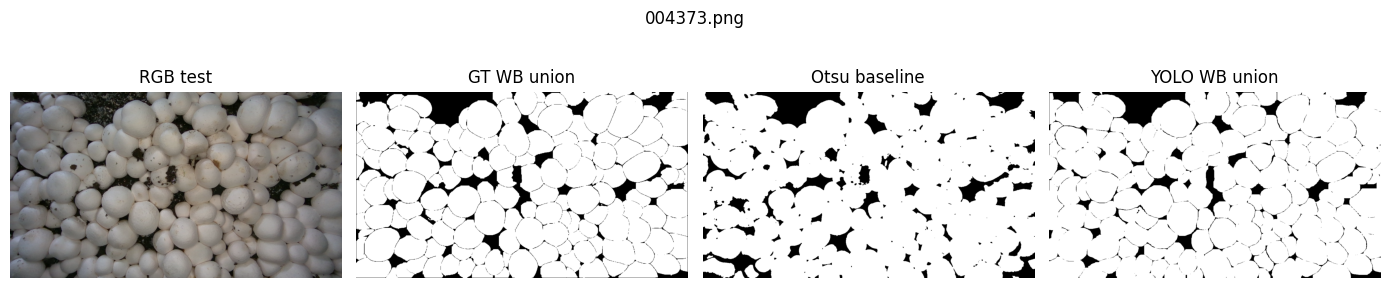

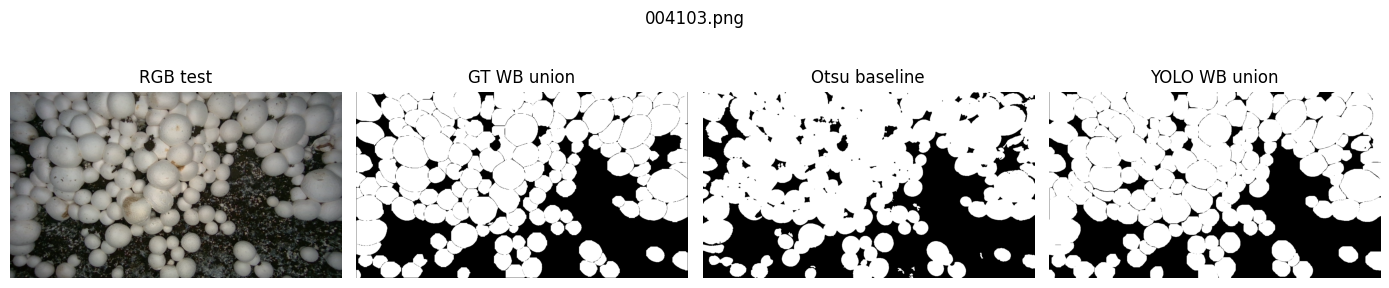

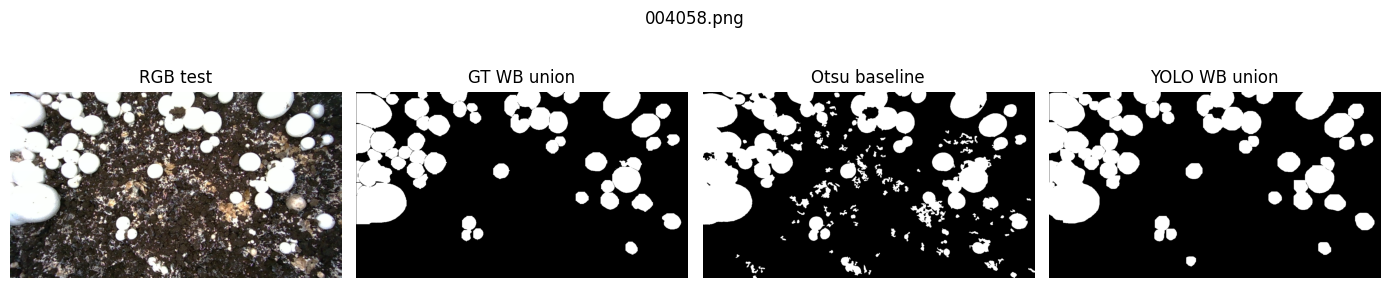

# M18K V2: Otsu Baseline and Ablation (small sample)

- Test images: 10 randomly sampled images (seed 42) from the held-out split.
- Methods: classical grayscale/Gaussian/Otsu/morphology/connected-components baseline,
  ablations removing blur or morphology, and existing WB-only YOLOv8n-seg checkpoint.
- All methods evaluated on the **same images** against the **WB COCO ground-truth foreground union**.
- Otsu implemented from scratch; OpenCV verification: 10/10 exact binary matches;
  minimum pixel agreement 1.00000.

| Method | Mean union IoU | Mean union Dice | Count MAE | Mean runtime (ms/image) |
|---|---:|---:|---:|---:|
| Otsu_full | 0.8662 | 0.9269 | 121.20 | 19.3 |
| Otsu_no_blur | 0.8709 | 0.9296 | 122.10 | 16.5 |
| Otsu_no_morph | 0.8648 | 0.9260 | 122.50 | 17.4 |
| YOLO_WB_only | 0.9201 | 0.9583 | 7.30 | 2797.8 |

**Interpretation:** These are foreground-union IoU and Dice scores, **not instance mask mAP**.
For the classical method, connected components approximate object co

In [9]:
for name,rgb,gt,otsu_mask,yolo_mask in previews:
    fig,axs = plt.subplots(1,4,figsize=(14,3.3))
    for ax,im,title in zip(axs,[rgb,gt,otsu_mask,yolo_mask],
                           ["RGB test", "GT WB union", "Otsu baseline", "YOLO WB union"]):
        ax.imshow(im,cmap="gray" if im.ndim==2 else None)
        ax.set_title(title); ax.axis("off")
    fig.suptitle(name); fig.tight_layout()
    fig.savefig(OUT / f"figure_{Path(name).stem}.png",dpi=115,bbox_inches="tight")
    plt.show()
    plt.close(fig)

# Build a concise experiment note, using measured numbers only.
method_rows = {r["method"]:r for r in summary.to_dict("records")}
report = f"""# M18K V2: Otsu Baseline and Ablation (small sample)

- Test images: {len(selected)} randomly sampled images (seed {SEED}) from the held-out split.
- Methods: classical grayscale/Gaussian/Otsu/morphology/connected-components baseline,
  ablations removing blur or morphology, and existing WB-only YOLOv8n-seg checkpoint.
- All methods evaluated on the **same images** against the **WB COCO ground-truth foreground union**.
- Otsu implemented from scratch; OpenCV verification: {int(checks.exact_match.sum())}/{len(checks)} exact binary matches;
  minimum pixel agreement {checks.pixel_agreement.min():.5f}.

| Method | Mean union IoU | Mean union Dice | Count MAE | Mean runtime (ms/image) |
|---|---:|---:|---:|---:|
"""
for r in summary.to_dict("records"):
    report += f"| {r['method']} | {r['mean_union_IoU']:.4f} | {r['mean_union_Dice']:.4f} | {r['count_MAE']:.2f} | {r['mean_runtime_ms']:.1f} |\n"
report += """
**Interpretation:** These are foreground-union IoU and Dice scores, **not instance mask mAP**.
For the classical method, connected components approximate object counts and can merge adjacent mushrooms.
The sample is small, and some M18K V2 annotations may contain anomalies.
YOLO and classical runtimes use different devices if CUDA is available, so speed is descriptive.
The reported process RSS is **not** an isolated per-method peak memory measurement.
"""
(OUT/"FINDINGS.md").write_text(report)
print(report)

archive=Path("/content/M18K_Otsu_Comparison_Results.zip")
with zipfile.ZipFile(archive,"w",zipfile.ZIP_DEFLATED) as z:
    for file in sorted(OUT.iterdir()):
        if file.is_file(): z.write(file,arcname=file.name)
print("Saved results:",archive)


## How to use the results in the report

- **R3:** Cite `otsu_scratch()` and the measured agreement with `cv2.threshold(...THRESH_OTSU)`. The custom histogram/variance calculation is written here, not copied from OpenCV.
- **R2:** Compare `Otsu_full` with `YOLO_WB_only` on the same images using **foreground-union IoU, Dice, count MAE**.
- **R5:** Contrast `Otsu_full` with `Otsu_no_blur` and `Otsu_no_morph`, changing one part at a time.
- **R1:** Methods used: grayscale conversion, Gaussian filtering, histogram thresholding, morphology, connected components; map these to your actual course lessons before claiming compliance.
- **Limitations:** Small sample, binary-vs-instance model differences, imperfect/possibly anomalous labels, and device-dependent runtimes. Neither this experiment nor the earlier YOLO instance mAP is a physical-area (mm²) evaluation.
